# **Step 7 of 7: Best Clustering Model Selection (HR Employees)**

Notebooks 02 to 06 looked at each algorithm on its own. Here **all five algorithms compete** on the same preprocessed data:

1. **Tune:** many parameter settings are tried for every algorithm (K-Means++: k; Hierarchical: linkage and k; DBSCAN: eps and min_samples; OPTICS: min_samples, eps / xi; HDBSCAN: min_cluster_size, min_samples, method).
2. **Best setting per algorithm:** the setting with the best silhouette that passes the **quality rules** (see below).
3. **Compare the 5 winners** with one **composite score**.
4. **Pick the best model**, describe its clusters and **save** it.

**Why a composite score?** Clustering has no true labels, so no single number can say "this is the best". Also, silhouette alone is unfair: DBSCAN-type methods ignore their noise points, so they are scored on the easy employees only. The composite score combines:

| Part | Weight | Meaning |
|---|---|---|
| Coverage-adjusted silhouette | 35% | silhouette x share of employees that got a cluster (noise is punished) |
| Calinski-Harabasz | 15% | between-cluster / within-cluster spread (higher is better) |
| Davies-Bouldin | 15% | cluster overlap (lower is better) |
| **Stability** | 25% | does the algorithm give the **same clusters** on two different 80% samples of the employees? (ARI) |
| Coverage | 10% | % of employees that belong to a cluster (not noise) |

Every part is rescaled to 0-1 across the 5 winners, then the weights are applied. The weights are a **business decision**: a table at the end shows if the winner changes when the weights change.

**Quality rules (for HR segments):** 2 to 10 clusters, at most 20% noise, and **every cluster has at least 3% of the employees** (a "segment" of 15 people is a list of special cases, not a segment).

The hidden true groups of the demo data are **not used** for the selection; they are only shown at the end to check the choice.

### 1. Import and load the preprocessed data (from step 1)

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

In [3]:
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS, HDBSCAN

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)

# ----- settings you can change -----
MIN_CLUSTER_SHARE = 3          # every cluster needs at least this % of the employees
MAX_NOISE = 20                 # at most this % of employees may be noise
WEIGHTS = {'adj_silhouette': 0.35, 'calinski_harabasz': 0.15, 'davies_bouldin': 0.15, 'stability': 0.25, 'coverage': 0.10}

### 2. Candidates: every algorithm with many parameter settings
Each candidate is one algorithm + one setting.

In [4]:
candidates = []     # (algorithm, parameters, estimator)

for k in range(2, 11):
    candidates.append(('K-Means++', {'k': k}, KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)))

for link in ['ward', 'complete', 'average']:
    for k in range(2, 11):
        candidates.append(('Hierarchical', {'linkage': link, 'k': k}, AgglomerativeClustering(n_clusters=k, linkage=link)))

for eps in np.round(np.arange(0.3, 1.55, 0.05), 2):
    for ms in [5, 8, 12, 16, 20]:
        candidates.append(('DBSCAN', {'eps': float(eps), 'min_samples': ms}, DBSCAN(eps=eps, min_samples=ms)))

for ms in [10, 20, 30]:
    for eps in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2]:
        candidates.append(('OPTICS', {'method': 'dbscan-cut', 'min_samples': ms, 'eps': eps}, OPTICS(min_samples=ms, cluster_method='dbscan', eps=eps)))
    for xi in [0.01, 0.03, 0.05, 0.1]:
        for mcs in [0.02, 0.05]:
            candidates.append(('OPTICS', {'method': 'xi', 'min_samples': ms, 'xi': xi, 'min_cluster_size': mcs}, OPTICS(min_samples=ms, xi=xi, min_cluster_size=mcs)))

for mcs in [10, 20, 30, 50, 80, 120]:
    for ms in [None, 5, 10, 20]:
        for method in ['eom', 'leaf']:
            candidates.append(('HDBSCAN', {'min_cluster_size': mcs, 'min_samples': ms, 'method': method},
                               HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=method)))

print('Candidates:', len(candidates))
print(pd.Series([c[0] for c in candidates]).value_counts().to_string())

Candidates: 254
DBSCAN          125
HDBSCAN          48
OPTICS           45
Hierarchical     27
K-Means++         9


### 3. Evaluate all candidates
Internal metrics (noise points are ignored in silhouette, CH and DB) + noise % + the size of the smallest cluster.

In [5]:
%%time
def evaluate(algo, params, est):
    lab = clone(est).fit_predict(X)
    m = internal_metrics(X, lab)
    sizes = pd.Series(lab[lab != -1]).value_counts()
    m['min_cluster_%'] = round(100 * sizes.min() / len(X), 1) if len(sizes) else np.nan
    return {'algo': algo, 'params': params, **m}

all_df = pd.DataFrame([evaluate(*c) for c in candidates])
all_df['est'] = [c[2] for c in candidates]
print('Evaluated:', len(all_df))
all_df.drop(columns='est').sort_values('silhouette', ascending=False).head(8).round(3)

Evaluated: 254
CPU times: user 51.5 s, sys: 98 ms, total: 51.6 s
Wall time: 52.1 s


,algo,params,n_clusters,noise_%,silhouette,calinski_harabasz,davies_bouldin,min_cluster_%
37,DBSCAN,"{'eps': 0.3, 'min_samples': 8}",3,98.1,0.751,786.824,0.333,0.5
172,OPTICS,"{'method': 'xi', 'min_samples': 10, 'xi': 0.05...",2,88.5,0.685,417.678,0.383,2.1
185,OPTICS,"{'method': 'xi', 'min_samples': 20, 'xi': 0.03...",3,73.3,0.664,1091.992,0.481,3.0
43,DBSCAN,"{'eps': 0.35, 'min_samples': 12}",2,98.2,0.657,89.677,0.490,0.8
193,OPTICS,"{'method': 'dbscan-cut', 'min_samples': 30, 'e...",3,48.5,0.645,2062.803,0.522,9.0
186,OPTICS,"{'method': 'xi', 'min_samples': 20, 'xi': 0.03...",3,58.1,0.636,1908.032,0.524,10.1
231,HDBSCAN,"{'min_cluster_size': 50, 'min_samples': None, ...",4,43.0,0.606,1804.897,0.564,3.7
79,DBSCAN,"{'eps': 0.7, 'min_samples': 16}",4,21.9,0.549,1843.570,0.700,14.1


**Overview of all candidates:** silhouette against % noise. The best candidates are in the top-left (high silhouette, little noise). Stars = the winner of each algorithm (chosen in the next step).

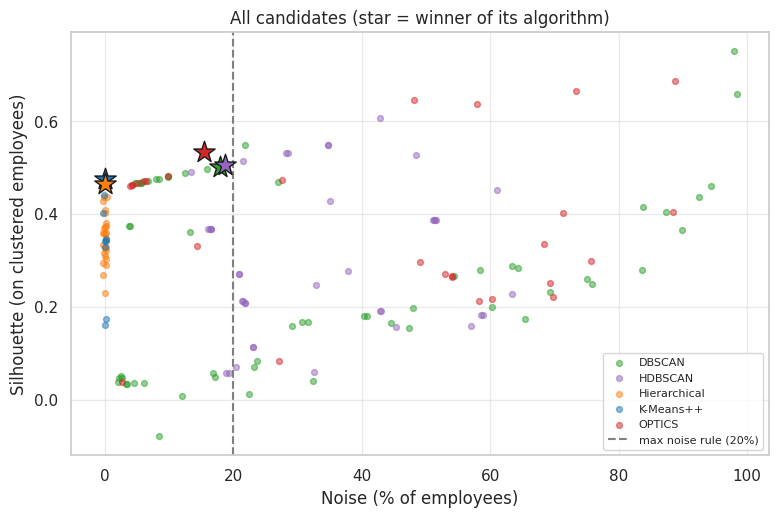

In [6]:
def valid_mask(res, max_noise, min_share):
    return (res['n_clusters'].between(2, 10) & (res['noise_%'] <= max_noise) &
            (res['min_cluster_%'] >= min_share) & res['silhouette'].notna())

winner_rows = []
for algo, g in all_df.groupby('algo', sort=False):
    for noise, share in [(MAX_NOISE, MIN_CLUSTER_SHARE), (35, 1)]:         # relax the rules only if nothing passes
        ok = g[valid_mask(g, noise, share)]
        if len(ok): break
    winner_rows.append(ok.sort_values('silhouette', ascending=False).iloc[0])
winners = pd.DataFrame(winner_rows).reset_index(drop=True)

plt.figure(figsize=(9, 5.5))
palette = dict(zip(all_df['algo'].unique(), sns.color_palette('tab10', 5)))
for algo, g in all_df.groupby('algo'):
    ok = g[g['silhouette'].notna()]
    plt.scatter(ok['noise_%'] + np.random.default_rng(0).uniform(-0.3, 0.3, len(ok)), ok['silhouette'], s=18, alpha=0.5, color=palette[algo], label=algo)
for _, w in winners.iterrows():
    plt.scatter(w['noise_%'], w['silhouette'], s=260, marker='*', color=palette[w['algo']], edgecolor='k', zorder=5)
plt.axvline(MAX_NOISE, color='gray', ls='--', label=f'max noise rule ({MAX_NOISE}%)')
plt.xlabel('Noise (% of employees)'); plt.ylabel('Silhouette (on clustered employees)'); plt.title('All candidates (star = winner of its algorithm)')
plt.legend(fontsize=8); plt.grid(alpha=0.4); plt.show()

### 4. Best setting of each algorithm
Highest silhouette among the candidates that pass the quality rules.

In [7]:
show = winners.drop(columns='est').copy()
show['params'] = show['params'].astype(str)
show.set_index('algo').round(3)

,params,n_clusters,noise_%,silhouette,calinski_harabasz,davies_bouldin,min_cluster_%
algo,,,,,,,
K-Means++,{'k': 4},4,0.0,0.474,1490.560,0.849,20.2
Hierarchical,"{'linkage': 'ward', 'k': 4}",4,0.0,0.465,1411.856,0.883,20.0
DBSCAN,"{'eps': 0.7, 'min_samples': 12}",3,18.0,0.500,1337.741,0.765,17.1
OPTICS,"{'method': 'dbscan-cut', 'min_samples': 30, 'e...",4,15.4,0.532,1802.527,0.730,16.6
HDBSCAN,"{'min_cluster_size': 30, 'min_samples': None, ...",3,18.8,0.506,1310.591,0.750,15.8


### 5. Stability test
For every winner: take **two different random 80% samples** of the employees, cluster each sample, and compare the clusters on the employees that are in both samples (ARI). 10 repeats. **1 = always the same clusters**, near 0 = clusters change with the sample (not trustworthy).

In [8]:
%%time
def stability(est, repeats=10, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); n = len(X); scores = []
    for _ in range(repeats):
        a = rng.choice(n, int(frac * n), replace=False); b = rng.choice(n, int(frac * n), replace=False)
        la, lb = np.full(n, -2), np.full(n, -2)
        la[a] = clone(est).fit_predict(X[a]); lb[b] = clone(est).fit_predict(X[b])
        both = (la != -2) & (lb != -2)
        scores.append(adjusted_rand_score(la[both], lb[both]))
    return np.mean(scores), np.std(scores)

st = [stability(e) for e in winners['est']]
winners['stability'] = [s[0] for s in st]
winners['stability_std'] = [s[1] for s in st]
winners[['algo', 'stability', 'stability_std']].set_index('algo').round(3)

CPU times: user 16.3 s, sys: 12 ms, total: 16.3 s
Wall time: 16.5 s


,stability,stability_std
algo,,
K-Means++,0.996,0.004
Hierarchical,0.906,0.033
DBSCAN,0.838,0.067
OPTICS,0.865,0.022
HDBSCAN,0.938,0.015


### 6. Composite score and ranking
`adj_silhouette = silhouette x (1 - noise%)`, `coverage = 100 - noise%`. All parts are rescaled to 0-1 across the 5 winners (for Davies-Bouldin lower is better, so it is reversed), then combined with the weights.

In [9]:
winners['adj_silhouette'] = winners['silhouette'] * (1 - winners['noise_%'] / 100)
winners['coverage'] = 100 - winners['noise_%']

def minmax(s, higher_is_better=True):
    rng_ = s.max() - s.min()
    out = (s - s.min()) / rng_ if rng_ > 0 else pd.Series(1.0, index=s.index)
    return out if higher_is_better else 1 - out

def composite(df_, weights):
    parts = pd.DataFrame({'adj_silhouette': minmax(df_['adj_silhouette']),
                          'calinski_harabasz': minmax(df_['calinski_harabasz']),
                          'davies_bouldin': minmax(df_['davies_bouldin'], higher_is_better=False),
                          'stability': minmax(df_['stability']),
                          'coverage': minmax(df_['coverage'])})
    return parts, 100 * sum(parts[k] * w for k, w in weights.items()) / sum(weights.values())

parts, winners['score'] = composite(winners, WEIGHTS)
parts.index = winners['algo']
ranking = winners.sort_values('score', ascending=False).reset_index(drop=True)
ranking.index += 1; ranking.index.name = 'Rank'
display(ranking[['algo', 'score', 'n_clusters', 'noise_%', 'min_cluster_%', 'silhouette', 'adj_silhouette',
                 'calinski_harabasz', 'davies_bouldin', 'stability']].round(3))

best_algo = ranking.iloc[0]['algo']
print('BEST MODEL:', best_algo, '| score =', round(ranking.iloc[0]['score'], 1), '| parameters:', ranking.iloc[0]['params'])

,algo,score,n_clusters,noise_%,min_cluster_%,silhouette,adj_silhouette,calinski_harabasz,davies_bouldin,stability
Rank,,,,,,,,,,
1,K-Means++,78.740,4,0.0,20.2,0.474,0.474,1490.560,0.849,0.996
2,OPTICS,58.086,4,15.4,16.6,0.532,0.450,1802.527,0.730,0.865
3,Hierarchical,53.565,4,0.0,20.0,0.465,0.465,1411.856,0.883,0.906
4,HDBSCAN,29.208,3,18.8,15.8,0.506,0.411,1310.591,0.750,0.938
5,DBSCAN,12.798,3,18.0,17.1,0.500,0.410,1337.741,0.765,0.838


BEST MODEL: K-Means++ | score = 78.7 | parameters: {'k': 4}


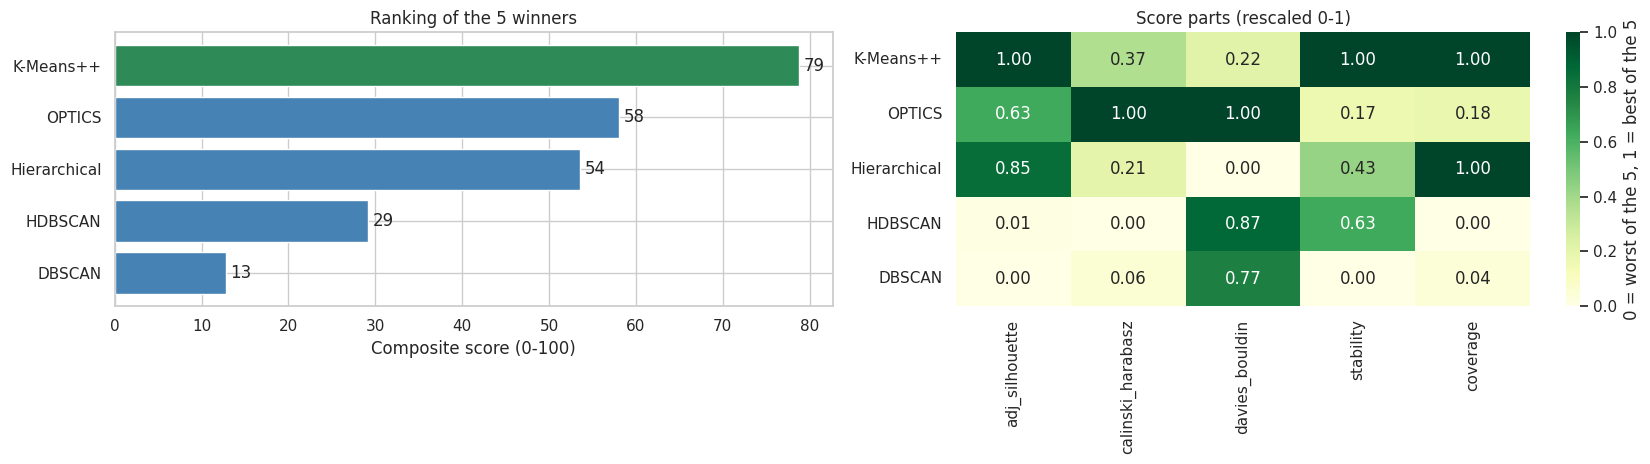

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
order = ranking['algo']
ax[0].barh(order, ranking['score'], color=['seagreen' if a == best_algo else 'steelblue' for a in order])
ax[0].invert_yaxis(); ax[0].set_xlabel('Composite score (0-100)'); ax[0].set_title('Ranking of the 5 winners')
for i, v in enumerate(ranking['score']): ax[0].text(v + 0.5, i, f'{v:.0f}', va='center')

sns.heatmap(parts.loc[order], annot=True, fmt='.2f', cmap='YlGn', vmin=0, vmax=1, ax=ax[1], cbar_kws={'label': '0 = worst of the 5, 1 = best of the 5'})
ax[1].set_title('Score parts (rescaled 0-1)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

**How to read the scores:** they are **relative**. 0 = the worst of the 5 winners, 1 = the best of the 5, so small raw differences become big score gaps. For example, in this run HDBSCAN's adjusted silhouette (0.411) is only 0.06 below K-Means++ (0.474), but its part score is 0.01. Always read the raw metrics in the table together with the ranking, and treat algorithms with almost the same raw metrics as tied. What separates the algorithms most here is **stability** and **coverage** (noise), not the cluster shape metrics.

### 7. Is the choice robust? Different weights
The weights are a business decision. If the same algorithm wins under every reasonable weighting, the choice is solid.

In [11]:
weight_sets = {
    'default':                    WEIGHTS,
    'equal weights':              {k: 1 for k in WEIGHTS},
    'cluster quality only':       {'adj_silhouette': 0.5, 'calinski_harabasz': 0.25, 'davies_bouldin': 0.25, 'stability': 0, 'coverage': 0},
    'stability + coverage first': {'adj_silhouette': 0.1, 'calinski_harabasz': 0, 'davies_bouldin': 0, 'stability': 0.5, 'coverage': 0.4},
    'silhouette only':            {'adj_silhouette': 1, 'calinski_harabasz': 0, 'davies_bouldin': 0, 'stability': 0, 'coverage': 0},
}
rows = []
for name, w in weight_sets.items():
    _, sc = composite(winners, w)
    r = pd.Series(sc.values, index=winners['algo'])
    rows.append({'weights': name, 'winner': r.idxmax(), **{a: round(v, 1) for a, v in r.items()}})
robust = pd.DataFrame(rows).set_index('weights')
display(robust)
print('Winner under each weighting:', robust['winner'].value_counts().to_dict())

,winner,K-Means++,Hierarchical,DBSCAN,OPTICS,HDBSCAN
weights,,,,,,
default,K-Means++,78.7,53.6,12.8,58.1,29.2
equal weights,K-Means++,71.7,49.7,17.3,59.6,30.2
cluster quality only,OPTICS,64.6,47.7,20.6,81.4,22.3
stability + coverage first,K-Means++,100.0,69.9,1.7,22.1,31.7
silhouette only,K-Means++,100.0,85.1,0.0,62.8,1.1


Winner under each weighting: {'K-Means++': 4, 'OPTICS': 1}


### 8. Side-by-side: the 5 winners (PCA 2D)
Black **x** = noise. Bottom right: the hidden true groups of the demo data (not used for the selection).

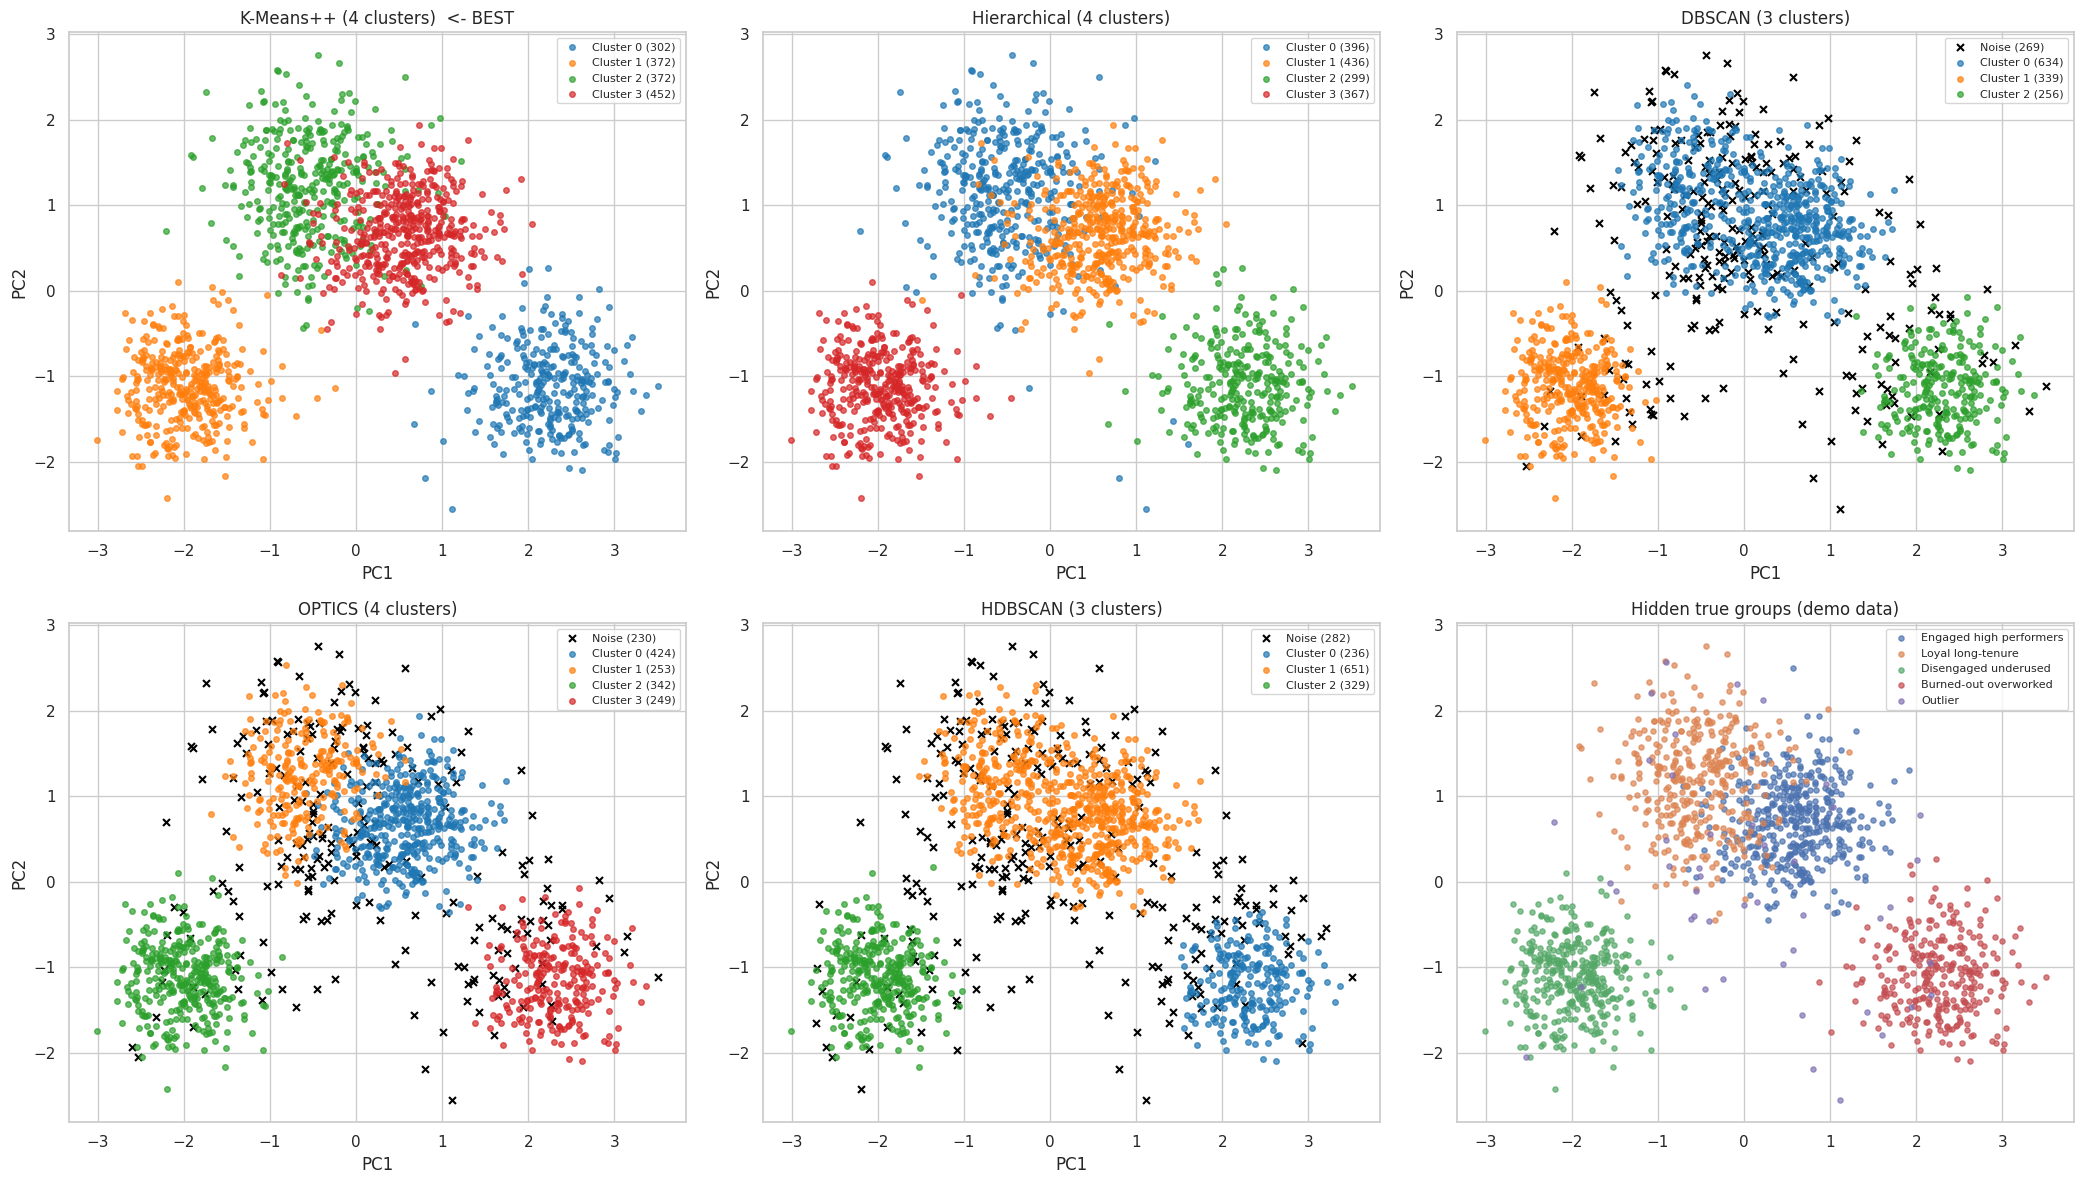

In [12]:
fits = {}
for _, w in winners.iterrows():
    fits[w['algo']] = clone(w['est']).fit_predict(X)

fig, ax = plt.subplots(2, 3, figsize=(21, 12))
for a, (algo, lab) in zip(ax.ravel(), fits.items()):
    star = '  <- BEST' if algo == best_algo else ''
    plot_clusters(Z, lab, a, f'{algo} ({len(set(lab) - {-1})} clusters){star}')
if HAS_TRUTH:
    codes, names = pd.factorize(df['segment_true'])
    for c, nm in enumerate(names):
        ax.ravel()[-1].scatter(Z[codes == c, 0], Z[codes == c, 1], s=14, alpha=0.7, label=nm)
    ax.ravel()[-1].set_title('Hidden true groups (demo data)'); ax.ravel()[-1].legend(fontsize=8)
else:
    ax.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

### 9. Check afterwards with the hidden true groups (demo data only)
This is **not** part of the score. It only shows whether the unsupervised selection chose well.

In [13]:
if HAS_TRUTH:
    chk = pd.DataFrame({algo: external_metrics(df['segment_true'], lab) for algo, lab in fits.items()}).T[['ARI', 'NMI']]
    chk['composite_score'] = winners.set_index('algo')['score']
    display(chk.sort_values('composite_score', ascending=False).round(3))
    print('Best by composite score :', chk['composite_score'].idxmax())
    print('Best by ARI (true groups):', chk['ARI'].idxmax())
else:
    print('No true groups available (real data): rely on the internal metrics, stability and the business meaning of the clusters.')

,ARI,NMI,composite_score
K-Means++,0.901,0.872,78.740
OPTICS,0.753,0.751,58.086
Hierarchical,0.894,0.871,53.565
HDBSCAN,0.544,0.636,29.208
DBSCAN,0.563,0.652,12.798


Best by composite score : K-Means++
Best by ARI (true groups): K-Means++


### 10. The best model: who is in each cluster?

Best algorithm : K-Means++
Parameters     : {'k': 4}
Clusters       : 4 | noise: 0 employees

Silhouette 0.474 | Calinski-Harabasz 1490.6 | Davies-Bouldin 0.849


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%,description
cluster,,,,,,,,,
0,0.27,0.87,5.98,270.61,3.92,0.53,302,20.2,"high average monthly hours, high number projec..."
1,0.40,0.52,2.46,147.11,3.16,0.53,372,24.8,"low last evaluation, low number project, low a..."
2,0.64,0.70,3.79,178.71,8.08,1.31,372,24.8,high time spend company
3,0.79,0.84,4.49,202.84,3.90,1.21,452,30.2,high satisfaction level


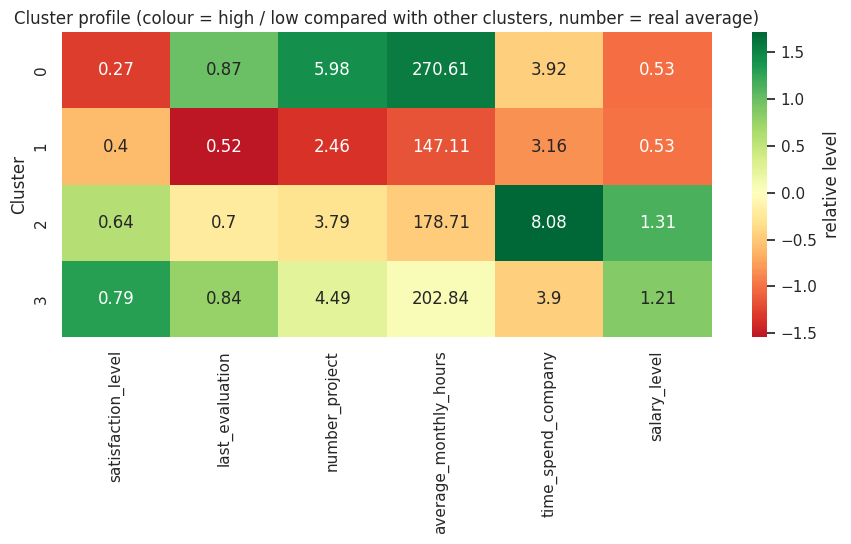

In [14]:
best_row = winners[winners['algo'] == best_algo].iloc[0]
best_est = clone(best_row['est'])
labels = best_est.fit_predict(X)

print('Best algorithm :', best_algo)
print('Parameters     :', best_row['params'])
print('Clusters       :', len(set(labels) - {-1}), '| noise:', int((labels == -1).sum()), 'employees')
print()
m = internal_metrics(X, labels)
print(f"Silhouette {m['silhouette']:.3f} | Calinski-Harabasz {m['calinski_harabasz']:.1f} | Davies-Bouldin {m['davies_bouldin']:.3f}")

prof = cluster_profile(df, labels)

# automatic description: features that are clearly higher / lower than the average employee
mu, sd = df[FEATURES].mean(), df[FEATURES].std()
def describe(row, cid):
    if cid == -1:
        return 'noise: unusual employees that fit no group'
    z = (row[FEATURES] - mu) / sd
    parts = [('high ' if v > 0 else 'low ') + f.replace('_', ' ') for f, v in z.sort_values(key=abs, ascending=False).items() if abs(v) >= 0.7]
    return ', '.join(parts) if parts else 'close to the average employee'
prof['description'] = [describe(r, cid) for cid, r in prof.iterrows()]
display(prof.round(2))
plot_profile(prof.drop(columns='description'))

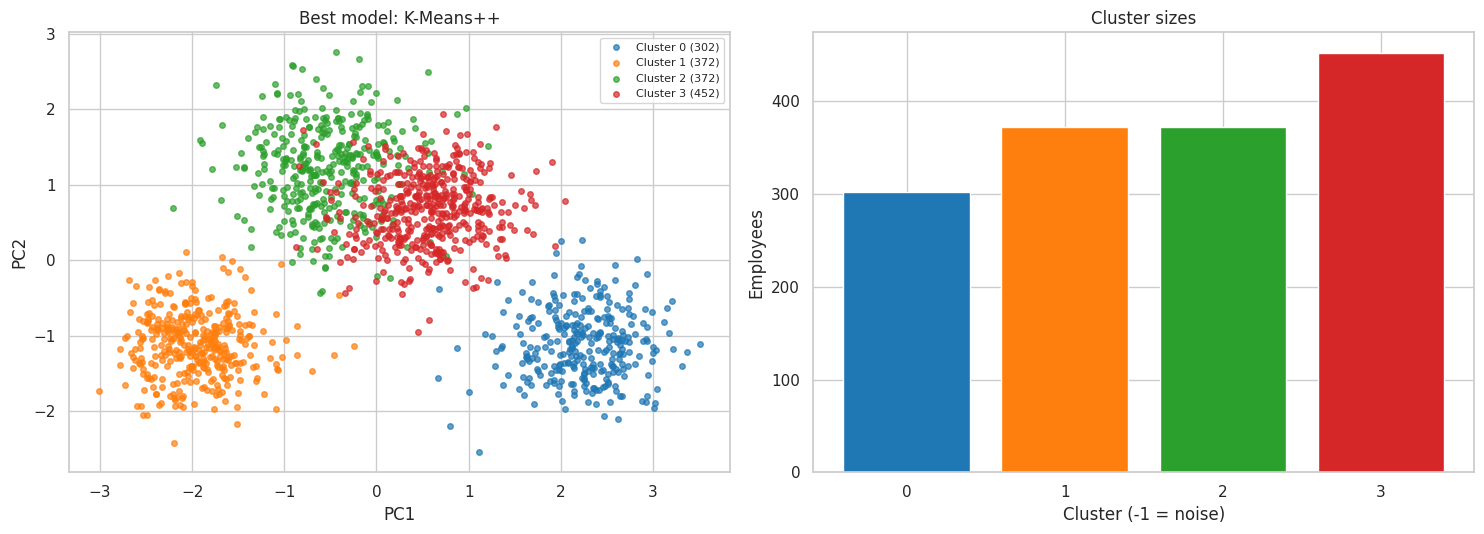

Attrition (employees who left) per cluster - a column that was NOT used for the clustering:


cluster,0,1,2,3
employees,302.0,372.0,372.0,452.0
left_rate,88.4,47.6,27.2,13.3


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
plot_clusters(Z, labels, ax[0], f'Best model: {best_algo}')
sizes = pd.Series(labels).value_counts().sort_index()
ax[1].bar(sizes.index.astype(str), sizes.values, color=['black' if i == -1 else sns.color_palette('tab10')[i % 10] for i in sizes.index])
ax[1].set_xlabel('Cluster (-1 = noise)'); ax[1].set_ylabel('Employees'); ax[1].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

# department and attrition (left) per cluster: columns that were NOT used for clustering
if 'left' in df.columns:
    extra = df.assign(cluster=labels).groupby('cluster').agg(employees=('employee_id', 'count'), left_rate=('left', 'mean'))
    extra['left_rate'] = (extra['left_rate'] * 100).round(1)
    print('Attrition (employees who left) per cluster - a column that was NOT used for the clustering:')
    display(extra.T)

### 11. Save the best model
`best_clustering_model.pkl` contains everything needed to place a **new** employee into a cluster:
the fitted scaler (from step 1), the model and, for algorithms without `predict` (all except K-Means), a KNN assigner trained on the found clusters.

In [16]:
mask = labels != -1
assigner = best_est if hasattr(best_est, 'predict') else KNeighborsClassifier(n_neighbors=5).fit(X[mask], labels[mask])

package = {'algorithm': best_algo, 'parameters': best_row['params'], 'scaler': scaler, 'model': best_est, 'assigner': assigner,
           'features': FEATURES, 'profile': prof, 'composite_score': float(best_row['score']), 'weights': WEIGHTS,
           'quality_rules': {'min_cluster_share_%': MIN_CLUSTER_SHARE, 'max_noise_%': MAX_NOISE}}
joblib.dump(package, 'best_clustering_model.pkl')

df.assign(cluster=labels).to_csv('hr_best_model_clusters.csv', index=False)
ranking.drop(columns='est').assign(params=ranking['params'].astype(str)).to_csv('clustering_model_selection_report.csv')
all_df.drop(columns='est').assign(params=all_df['params'].astype(str)).to_csv('all_candidates_leaderboard.csv', index=False)
prof.to_csv('best_model_cluster_profile.csv')
print('Saved: best_clustering_model.pkl, hr_best_model_clusters.csv, clustering_model_selection_report.csv,')
print('       all_candidates_leaderboard.csv, best_model_cluster_profile.csv')

Saved: best_clustering_model.pkl, hr_best_model_clusters.csv, clustering_model_selection_report.csv,
       all_candidates_leaderboard.csv, best_model_cluster_profile.csv


### 12. Use the saved model on new employees
The values are in **original units** (the saved scaler prepares them).

In [17]:
pkg = joblib.load('best_clustering_model.pkl')
new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45, 0.60], 'last_evaluation': [0.90, 0.88, 0.50, 0.72],
                    'number_project': [7, 5, 2, 4], 'average_monthly_hours': [280, 210, 140, 185],
                    'time_spend_company': [4, 3, 3, 8]})
new['cluster'] = pkg['assigner'].predict(pkg['scaler'].transform(new[pkg['features']]))
new['cluster_description'] = new['cluster'].map(pkg['profile']['description'])
new

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster,cluster_description
0,0.15,0.90,7,280,4,0,"high average monthly hours, high number projec..."
1,0.85,0.88,5,210,3,3,high satisfaction level
2,0.45,0.50,2,140,3,1,"low last evaluation, low number project, low a..."
3,0.60,0.72,4,185,8,2,high time spend company


### 13. Download (Google Colab only)

In [18]:
try:
    from google.colab import files
    for f in ['best_clustering_model.pkl', 'hr_best_model_clusters.csv', 'clustering_model_selection_report.csv',
              'all_candidates_leaderboard.csv', 'best_model_cluster_profile.csv']:
        files.download(f)
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
